# Comparing judges with humans, answer the research questions, releasing the benchmark

Reads the human ratings (Notebook 8) and the judge ratings (Notebook 9) **for the same items** and produces:

| Research question | Table / figure | What it answers |
|---|---|---|
| RQ1 overall agreement | `rq1_overall.csv`, `rq1_by_question.csv`, heatmap | How close is each judge (and setup) to the human annotators - compared with how close annotators are to *each other* |
| RQ2 historical vs synthetic | `rq2_by_source.csv` | Is agreement different when the profile is inferred (historical) vs stated (synthetic)? |
| RQ3 technique ranking | `rq3_technique_means.csv` | Do judges rank the four explanation techniques like humans? |
| RQ4 error detection | `rq4_detection.csv`, bar chart | Which judge setup catches which injected error (invented preference, wrong nutrition, ignored time limit, ignored diet)? |
| extras | `pairwise.csv`, `stability.csv` | pairwise agreement and position bias; repeat-to-repeat stability |

and finally an `insights.md` summary and a `release/` folder (the benchmark).

**Works with any amount of human data** - pilot only (3 annotators, 10 items), main with a single annotator, or everything. Every table has an `n` column, and the notebook prints plain warnings when numbers are too small to mean much. With **one** annotator there is no human-vs-human baseline; the notebook then says "human reliability unknown" instead of inventing one.

In [1]:
import sys, re, json, itertools, shutil, warnings
from pathlib import Path
from collections import Counter

import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt


def find_project_root() -> Path:
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "src" / "config.py").exists():
            return p
    raise FileNotFoundError("Open the notebook from inside the FoodJudgeBench folder.")


ROOT = find_project_root(); sys.path.insert(0, str(ROOT / "src"))
from config import PROC_DIR

BANK, ANN, JUDG = PROC_DIR / "case_bank", PROC_DIR / "annotations", PROC_DIR / "judgments"
RES = PROC_DIR / "results"; RES.mkdir(exist_ok=True)
print("project root:", ROOT)

project root: C:\HP Data\University-Masters\Semester_3\P1_Natural Language Processing\Lab\Project\FoodJudgeBench


#### 1. Settings

In [2]:
HUMAN_FILES = ["annotations_pilot_raw.csv"]       # same list as in 9_LLM_Judge.ipynb (use ["annotations_pilot_raw.csv", "annotations_main_raw.csv"] for both)
INCLUDE_MOCK = False          # mock judges give random answers: never include them in real results
RQ1_ON_SHARED_ITEMS = True    # with 2+ annotators: compare judges only on items that 2+ humans rated, so judge-vs-human and human-vs-human use the same items
MIN_N_WARN = 20               # warn when a number rests on fewer than this many ratings
RELEASE_NAME = "FoodJudgeBench_v0.1"
RELEASE_RECIPE_TEXT = False   # False: recipe titles/ingredients are withheld in the public release (Food.com terms: educational/scientific use) - ask your supervisor before switching to True
RELEASE_RATER_COMMENTS = False

#### 2. Load humans, judges, answer key, rubric

In [3]:
spec = json.load(open(BANK / "rubric.json", encoding="utf-8"))
RUBRIC, COLS = spec["rubric"], spec["columns"]
RTYPE = {r["id"]: r["type"] for r in RUBRIC}
YN = [r["id"] for r in RUBRIC if r["type"].startswith("yn")]
SCALE = [r["id"] for r in RUBRIC if r["type"].startswith("scale")]
PROBLEMS = ["ignored_constraint", "factual_error", "invented_personalization", "unsupported_claim"]
key = pd.read_csv(BANK / "answer_key.csv").set_index("case_id")

hum = pd.concat([pd.read_csv(ANN / f, dtype=str, keep_default_na=False).assign(_src=f) for f in HUMAN_FILES], ignore_index=True)
dups = hum.duplicated(["annotator_id", "case_id"], keep="last").sum()
if dups: print(f"{dups} rows rated by the same annotator in more than one file (e.g. pilot items re-rated in the main round): keeping the LAST file's rating")
hum = hum.drop_duplicates(["annotator_id", "case_id"], keep="last")
ANNOTATORS = sorted(hum["annotator_id"].unique())
ids = set(hum["case_id"])

jfiles = sorted(JUDG.glob("judgments_*.csv"))
assert jfiles, "no judgment files: run 9_LLM_Judge.ipynb first"
jud = pd.concat([pd.read_csv(f, dtype=str, keep_default_na=False) for f in jfiles], ignore_index=True)
if not INCLUDE_MOCK:
    n0 = len(jud); jud = jud[jud["judge"] != "mock"]
    if len(jud) < n0: print(f"ignored {n0-len(jud)} mock-judge rows")
jud = jud[jud["case_id"].isin(ids) & (jud["parse_error"] == "")]
JSETS = sorted(jud["annotator_id"].unique())
print(f"humans: {len(ANNOTATORS)} annotator(s) {ANNOTATORS}, {len(ids)} items;  judges x setups: {len(JSETS)}")
if len(ANNOTATORS) == 1:
    print("NOTE: only one human annotator -> judge-vs-human agreement is shown, but the human-vs-human baseline (how reliable humans are) cannot be computed.")
if hum["item_type"].eq("case").sum() + hum["item_type"].eq("diagnostic").sum() < MIN_N_WARN:
    print(f"NOTE: fewer than {MIN_N_WARN} human-rated items: treat every number below as a pipeline demonstration, not a result.")

humans: 3 annotator(s) ['A1', 'A2', 'A3'], 10 items;  judges x setups: 9


#### 3. Helpers: label tables, agreement metrics

In [4]:
def cohen_kappa(a, b, weights=None, cats=None):
    a, b = list(a), list(b)
    if not a: return np.nan
    cats = cats if cats is not None else sorted(set(a) | set(b)); k = len(cats); idx = {c: i for i, c in enumerate(cats)}
    O = np.zeros((k, k))
    for x, y in zip(a, b): O[idx[x], idx[y]] += 1
    O /= O.sum(); E = np.outer(O.sum(1), O.sum(0))
    i, j = np.indices((k, k))
    W = (i != j).astype(float) if weights is None else ((i - j) / max(k - 1, 1)) ** 2
    den = (W * E).sum()
    return np.nan if den == 0 else 1 - (W * O).sum() / den


def agg(values, qtype):
    """combine several ratings (several repeats of a judge) into one label"""
    v = [x for x in values if x not in ("", None)]
    if not v: return None
    if qtype in ("yn", "yn_na"):
        c = Counter(v).most_common()
        return c[0][0] if len(c) == 1 or c[0][1] > c[1][1] else None
    na = sum(x == "na" for x in v)
    if na * 2 > len(v): return "na"
    nums = [int(x) for x in v if x != "na"]
    return str(int(np.floor(np.median(nums) + 0.5))) if nums else "na"


def label_table(df):
    """df: rows of ONE rater (annotator or judge|setup); returns case_id -> {question: label}"""
    out = {}
    for cid, g in df[df["item_type"] != "pair"].groupby("case_id"):
        out[cid] = {q: agg(g[q].tolist(), RTYPE[q]) for q in YN + SCALE}
    return pd.DataFrame.from_dict(out, orient="index")


def pair_table(df):
    out = {}
    for cid, g in df[df["item_type"] == "pair"].groupby("case_id"):
        c = Counter(x for x in g["pair_choice"] if x).most_common()
        out[cid] = c[0][0] if c and (len(c) == 1 or c[0][1] > c[1][1]) else None
    return pd.Series(out, dtype=object)


H = {a: label_table(hum[hum["annotator_id"] == a]) for a in ANNOTATORS}
J = {s: label_table(jud[jud["annotator_id"] == s]) for s in JSETS}
HP = {a: pair_table(hum[hum["annotator_id"] == a]) for a in ANNOTATORS}
JP = {s: pair_table(jud[jud["annotator_id"] == s]) for s in JSETS}


def pairs_frame(X, Y, name_x, name_y):
    """aligned label pairs for two raters (X = reference, Y = other)"""
    common = X.index.intersection(Y.index)
    rows = []
    for q in YN + SCALE:
        for c in common:
            x, y = X.at[c, q], Y.at[c, q]
            if x is None or y is None or (isinstance(x, float) and x != x): continue
            rows.append((name_x, name_y, c, q, x, y))
    return pd.DataFrame(rows, columns=["x", "y", "case_id", "q", "h", "j"])


def q_metrics(q, h, j):
    h, j = list(h), list(j)
    n = len(h)
    if n == 0: return {"n": 0}
    m = {"n": n, "exact": float(np.mean([a == b for a, b in zip(h, j)]))}
    if RTYPE[q] in ("yn", "yn_na"):
        both = [(a, b) for a, b in zip(h, j) if a in ("yes", "no") and b in ("yes", "no")]     # kappa only where both said yes/no
        m["n_yesno"] = len(both)
        m["kappa"] = cohen_kappa([a for a, _ in both], [b for _, b in both]) if both else np.nan
        if RTYPE[q] == "yn_na": m["na_agree"] = float(np.mean([(a == "na") == (b == "na") for a, b in zip(h, j)]))
        tp = sum(a == "yes" and b == "yes" for a, b in zip(h, j)); fp = sum(a != "yes" and b == "yes" for a, b in zip(h, j)); fn = sum(a == "yes" and b != "yes" for a, b in zip(h, j))
        m["precision"] = tp / (tp + fp) if tp + fp else np.nan
        m["recall"] = tp / (tp + fn) if tp + fn else np.nan
        m["f1"] = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else np.nan
        m["human_yes"] = float(np.mean([a == "yes" for a in h])); m["other_yes"] = float(np.mean([b == "yes" for b in j]))
    else:
        m["na_agree"] = float(np.mean([(a == "na") == (b == "na") for a, b in zip(h, j)]))
        num = [(int(a), int(b)) for a, b in zip(h, j) if a != "na" and b != "na"]
        if num:
            x, y = np.array(num).T
            m["n_numeric"] = len(num); m["within_1"] = float(np.mean(abs(x - y) <= 1)); m["mae"] = float(np.mean(abs(x - y)))
            m["bias"] = float(np.mean(y - x))
            m["spearman"] = float(pd.Series(x).corr(pd.Series(y), method="spearman")) if len(set(x)) > 1 and len(set(y)) > 1 and len(num) >= 4 else np.nan
            m["qw_kappa"] = cohen_kappa(x, y, weights="quadratic", cats=[1, 2, 3, 4, 5])
    return m


def summarize(pf):
    """one row per question + overall summary for a frame of aligned pairs"""
    per = {q: q_metrics(q, g["h"], g["j"]) for q, g in pf.groupby("q")}
    perdf = pd.DataFrame(per).T.reindex([q for q in YN + SCALE if q in per])
    def mean(col, qs):
        if col not in perdf or not any(q in perdf.index for q in qs): return np.nan
        v = perdf.loc[[q for q in qs if q in perdf.index], col].astype(float).dropna()
        return float(v.mean()) if len(v) else np.n
    with np.errstate(all="ignore"):
        s = {"n_ratings": int(perdf["n"].sum()) if len(perdf) else 0, "yn_exact": mean("exact", YN), "yn_kappa": mean("kappa", YN), "yn_f1": mean("f1", YN),
             "scale_within_1": mean("within_1", SCALE), "scale_spearman": mean("spearman", SCALE), "scale_qw_kappa": mean("qw_kappa", SCALE), "scale_mae": mean("mae", SCALE)}
    return s, perdf

#### 4. RQ1 - overall agreement
Each judge|setup is compared with **each annotator separately** (same items), and annotators are compared with each other the same way, so "judge vs human" and "human vs human" are measured on the same footing. Higher kappa / Spearman / within-1 = closer agreement. A judge that reaches the human-vs-human level is "as reliable as a human annotator" on this data.

In [5]:
def frames_judge_vs_human(sets=None, case_filter=None):
    fr = []
    for s in (sets or JSETS):
        for a in ANNOTATORS:
            p = pairs_frame(H[a], J[s], a, s)
            if case_filter is not None: p = p[p["case_id"].isin(case_filter)]
            fr.append(p)
    return pd.concat(fr, ignore_index=True) if fr else pd.DataFrame(columns=["x", "y", "case_id", "q", "h", "j"])


def frames_human_vs_human(case_filter=None):
    fr = []
    for a, b in itertools.permutations(ANNOTATORS, 2):          # both directions, so the metric is symmetric
        p = pairs_frame(H[a], H[b], a, b)
        if case_filter is not None: p = p[p["case_id"].isin(case_filter)]
        fr.append(p)
    return pd.concat(fr, ignore_index=True) if fr else pd.DataFrame(columns=["x", "y", "case_id", "q", "h", "j"])

def bootstrap_ci(pf, reps=300, seed=0):
    """95% interval obtained by resampling ITEMS (rating pairs of one item are not independent)"""
    rng = np.random.default_rng(seed); groups = {c: g for c, g in pf.groupby("case_id")}; cases = list(groups)
    if len(cases) < 5: return {}
    res = []
    for _ in range(reps):
        pick = rng.choice(len(cases), len(cases), replace=True)
        res.append(summarize(pd.concat([groups[cases[i]] for i in pick], ignore_index=True))[0])
    d = pd.DataFrame(res); out = {}
    for k in ["yn_kappa", "scale_within_1", "scale_spearman"]:
        out[k + "_lo"], out[k + "_hi"] = float(d[k].quantile(.025)), float(d[k].quantile(.975))
    return out

rows, byq = [], []
n_raters = hum.groupby("case_id")["annotator_id"].nunique()
SHARED = set(n_raters[n_raters >= 2].index) if (len(ANNOTATORS) >= 2 and RQ1_ON_SHARED_ITEMS and (n_raters >= 2).any()) else None
if SHARED is not None: print(f"RQ1/RQ2 use the {len(SHARED)} items rated by 2+ annotators (RQ1_ON_SHARED_ITEMS = True); the other {len(ids)-len(SHARED)} items still count in RQ3/RQ4.")
if len(ANNOTATORS) >= 2:
    hh = frames_human_vs_human(SHARED)
    if len(hh):
        s, per = summarize(hh); rows.append({"rater": "HUMAN vs HUMAN (baseline)", "items_judged": hh["case_id"].nunique(), **s, **bootstrap_ci(hh)}); byq.append(per.assign(rater="HUMAN vs HUMAN (baseline)"))
jh = frames_judge_vs_human(case_filter=SHARED)
for sname, g in jh.groupby("y"):
    s, per = summarize(g); rows.append({"rater": sname, "items_judged": g["case_id"].nunique(), **s, **bootstrap_ci(g)}); byq.append(per.assign(rater=sname))
rq1 = pd.DataFrame(rows).set_index("rater")
rq1_q = pd.concat(byq).reset_index().rename(columns={"index": "question"}) if byq else pd.DataFrame()
rq1.round(3).to_csv(RES / "rq1_overall.csv"); rq1_q.round(3).to_csv(RES / "rq1_by_question.csv", index=False)
n_target = len(SHARED) if SHARED is not None else len(ids)
rq1["coverage"] = (rq1["items_judged"] / n_target).clip(upper=1).round(2)
show = rq1[["items_judged", "coverage", "n_ratings", "yn_exact", "yn_kappa", "yn_kappa_lo", "yn_kappa_hi", "yn_f1", "scale_within_1", "scale_within_1_lo", "scale_within_1_hi", "scale_spearman", "scale_qw_kappa", "scale_mae"]]
print(show.round(2).to_string())
print("\nHow to read: yn_kappa / scale_qw_kappa: 0 = chance, 1 = perfect.  scale_within_1: share of scores within 1 point.  yn_f1: how well 'yes' (a problem found) is matched.")
if rq1["n_ratings"].min() < MIN_N_WARN * 5: print(f"CAUTION: small samples (smallest row: {int(rq1['n_ratings'].min())} rating pairs over all questions).")

RQ1/RQ2 use the 10 items rated by 2+ annotators (RQ1_ON_SHARED_ITEMS = True); the other 0 items still count in RQ3/RQ4.
                           items_judged  coverage  n_ratings  yn_exact  yn_kappa  yn_kappa_lo  yn_kappa_hi  yn_f1  scale_within_1  scale_within_1_lo  scale_within_1_hi  scale_spearman  scale_qw_kappa  scale_mae
rater                                                                                                                                                                                                             
HUMAN vs HUMAN (baseline)            10       1.0        600      0.65      0.22        -0.02         0.40   0.42            0.88               0.78               0.95            0.36            0.38       0.78
gemma9b|checklist                    10       1.0        300      0.63      0.12        -0.05         0.40   0.33            0.83               0.71               0.91            0.39            0.31       0.81
gemma9b|rubric_facts                

**Per-question view** (kappa for yes/no questions, Spearman for 1-5 scales): where do judges fail?

question                   ignored_constraint  factual_error  invented_personalization  unsupported_claim  overstated_certainty  clarity  profile_fit  goal_alignment  tradeoff  overall
rater                                                                                                                                                                                   
HUMAN vs HUMAN (baseline)               -0.03           0.37                      0.47               0.25                  0.03     0.26         0.47           -0.20      0.68     0.60
gemma9b|checklist                         NaN           0.22                      0.53               0.25                 -0.52     0.34         0.72           -0.45      0.67     0.65
gemma9b|rubric_facts                      NaN           0.00                      0.13               0.18                  0.00     0.44         0.50           -0.45      0.78     0.63
gemma9b|rubric_nofacts                    NaN           0.00               

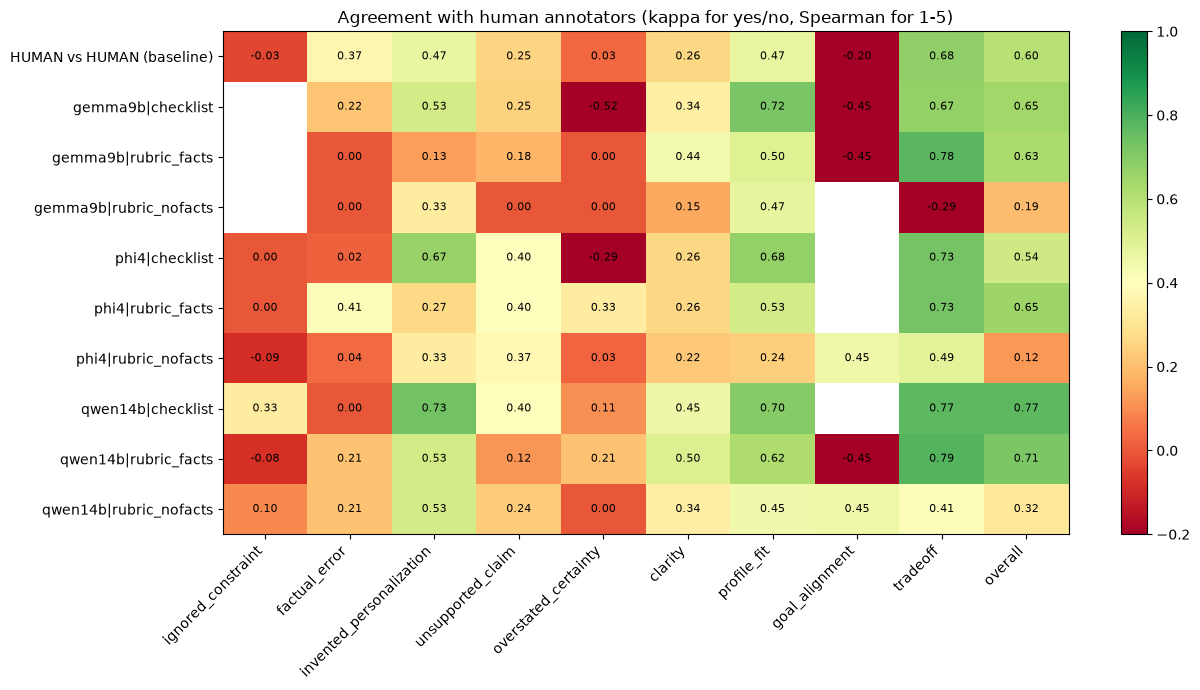

In [6]:
if len(rq1_q):
    heat = rq1_q.assign(score=np.where(rq1_q["question"].isin(YN), rq1_q.get("kappa"), rq1_q.get("spearman")).astype(float)).pivot(index="rater", columns="question", values="score").reindex(columns=[q for q in YN + SCALE])
    print(heat.round(2).to_string())
    fig, ax = plt.subplots(figsize=(1.0 * len(heat.columns) + 3, 0.5 * len(heat) + 2))
    im = ax.imshow(heat.values.astype(float), cmap="RdYlGn", vmin=-0.2, vmax=1, aspect="auto")
    ax.set_xticks(range(len(heat.columns))); ax.set_xticklabels(heat.columns, rotation=45, ha="right"); ax.set_yticks(range(len(heat))); ax.set_yticklabels(heat.index)
    for i in range(heat.shape[0]):
        for j in range(heat.shape[1]):
            v = heat.values[i, j]
            if v == v: ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
    ax.set_title("Agreement with human annotators (kappa for yes/no, Spearman for 1-5)"); fig.colorbar(im); fig.tight_layout()
    fig.savefig(RES / "fig_rq1_heatmap.png", dpi=150); plt.show()

#### 5. RQ2 - historical (inferred) vs synthetic (stated) profiles

In [7]:
src = key["profile_source"]
rq2 = []
for source in ["historical", "synthetic"]:
    cf = set(src[src == source].index)
    if SHARED is not None: cf = cf & SHARED
    if len(ANNOTATORS) >= 2:
        hh = frames_human_vs_human(cf)
        if len(hh): s, _ = summarize(hh); rq2.append({"source": source, "rater": "HUMAN vs HUMAN", **s})
    jh_s = frames_judge_vs_human(case_filter=cf)
    for sname, g in jh_s.groupby("y"):
        s, _ = summarize(g); rq2.append({"source": source, "rater": sname, **s})
rq2 = pd.DataFrame(rq2)
if len(rq2):
    rq2.round(3).to_csv(RES / "rq2_by_source.csv", index=False)
    print(rq2.pivot(index="rater", columns="source", values=["n_ratings", "yn_kappa", "scale_within_1", "scale_spearman"]).round(2).to_string())
    print("\nRead: a column that is much lower means judges (or humans) agree less on that kind of profile. Few items per source -> only a hint.")

                        n_ratings             yn_kappa           scale_within_1           scale_spearman          
source                 historical synthetic historical synthetic     historical synthetic     historical synthetic
rater                                                                                                             
HUMAN vs HUMAN              360.0     240.0       0.23      0.11           0.83      0.91           0.24      0.44
gemma9b|checklist           180.0     120.0       0.06      0.37           0.73      0.91           0.28      0.48
gemma9b|rubric_facts        180.0     120.0       0.00      0.37           0.77      0.90           0.31      0.51
gemma9b|rubric_nofacts      180.0     120.0      -0.03      0.37           0.65      0.81          -0.18      0.25
phi4|checklist              180.0     120.0       0.13      0.41           0.80      0.85           0.52      0.39
phi4|rubric_facts           180.0     120.0       0.32      0.24           0.83 

#### 6. RQ3 - do judges rank the four techniques like humans?
Only normal cases (not diagnostics). Higher `overall` = better; lower `problem_rate` = better.

In [8]:
tech = key["technique"]
def tech_means(labels_by_rater):
    rows = []
    for rname, T in labels_by_rater.items():
        T = T[T.index.isin(tech[tech.isin(["template", "direct_llm", "grounded_llm", "grounded_check_llm"])].index)]
        for t, idx in tech.reindex(T.index).groupby(tech.reindex(T.index)):
            sub = T.loc[idx.index]
            ov = pd.to_numeric(sub["overall"], errors="coerce")
            prob = np.nanmean([(sub[q] == "yes").sum() / max((sub[q].isin(["yes", "no"])).sum(), 1) for q in PROBLEMS])
            rows.append({"rater": rname, "technique": t, "n": len(sub), "overall_mean": ov.mean(), "problem_rate": prob})
    return pd.DataFrame(rows)


tm = pd.concat([tech_means({f"HUMAN {a}": H[a] for a in ANNOTATORS}), tech_means(J)], ignore_index=True)
if len(tm):
    tm.round(3).to_csv(RES / "rq3_technique_means.csv", index=False)
    order = ["template", "direct_llm", "grounded_llm", "grounded_check_llm"]
    pv = tm.pivot(index="rater", columns="technique", values="overall_mean").reindex(columns=[o for o in order if o in set(tm["technique"])])
    print("mean 'overall' (1-5) by technique:\n", pv.round(2).to_string())
    print("\nn per technique (per rater):", tm.groupby("technique")["n"].max().to_dict())
    hum_rows = [r for r in pv.index if r.startswith("HUMAN")]
    if hum_rows:
        href = pv.loc[hum_rows].mean()
        rk = []
        for r in pv.index:
            if r in hum_rows: continue
            a, b = href.dropna(), pv.loc[r].dropna(); common = a.index.intersection(b.index)
            rk.append({"judge|setup": r, "techniques": len(common), "spearman_with_human_ranking": float(a[common].corr(b[common], method="spearman")) if len(common) >= 3 else np.nan})
        if rk:
            print("\nranking agreement with the human average (only 3-4 techniques: indicative only):"); print(pd.DataFrame(rk).round(2).to_string(index=False))
    if tm["n"].max() < 10: print("\nCAUTION: fewer than 10 items per technique - the ranking is not meaningful yet (this is a pipeline demonstration).")

mean 'overall' (1-5) by technique:
 technique               template  direct_llm  grounded_llm  grounded_check_llm
rater                                                                         
HUMAN A1                     2.0         2.0           3.0                 3.5
HUMAN A2                     4.0         2.0           3.5                 4.5
HUMAN A3                     3.5         1.5           3.5                 4.5
gemma9b|checklist            3.5         2.5           3.0                 4.5
gemma9b|rubric_facts         3.5         3.0           3.5                 3.5
gemma9b|rubric_nofacts       3.5         3.5           3.0                 3.0
phi4|checklist               4.0         2.0           3.5                 3.5
phi4|rubric_facts            4.0         2.5           3.5                 3.5
phi4|rubric_nofacts          4.0         2.5           3.0                 2.5
qwen14b|checklist            4.5         1.5           3.5                 5.0
qwen14b|rubric_f

#### 7. RQ4 - which judge setup catches which injected error?
**Detection rate** = share of ratings on diagnostic items where the matching question was answered "yes". **Yes-rate on normal cases** is the same question on ordinary items (it includes real, natural errors, so it is a rough false-alarm level, not a pure one).

error                   invented_preference
rater                                      
HUMAN A1                                1.0
HUMAN A2                                0.5
HUMAN A3                                1.0
gemma9b|checklist                       1.0
gemma9b|rubric_facts                    0.5
gemma9b|rubric_nofacts                  1.0
phi4|checklist                          1.0
phi4|rubric_facts                       1.0
phi4|rubric_nofacts                     1.0
qwen14b|checklist                       1.0
qwen14b|rubric_facts                    1.0
qwen14b|rubric_nofacts                  1.0

items per error type: {'invented_preference': 2}
Error types with NO rated item in these files: ['ignored_dietary_constraint', 'ignored_time_limit', 'wrong_nutrition']


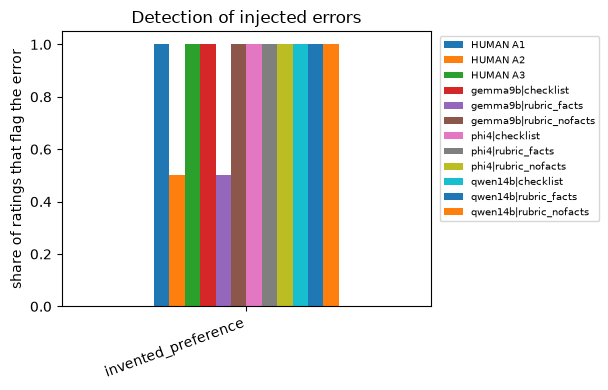

In [9]:
FLAG = {"invented_preference": "invented_personalization", "wrong_nutrition": "factual_error",
        "ignored_time_limit": "ignored_constraint", "ignored_dietary_constraint": "ignored_constraint"}
diag = key[key["item_type"] == "diagnostic"]
rq4 = []
def det_rows(rname, T):
    for etype, q in FLAG.items():
        ids_e = diag.index[diag["injected_error"] == etype].intersection(T.index)
        if not len(ids_e): continue
        rq4.append({"rater": rname, "error": etype, "question": q, "n_items": len(ids_e), "detected": float(np.mean([T.at[c, q] == "yes" for c in ids_e])),
                    "yes_rate_on_normal_cases": float(np.mean([T.at[c, q] == "yes" for c in T.index.intersection(key.index[key["item_type"] == "case"])])) if len(T.index.intersection(key.index[key["item_type"] == "case"])) else np.nan})
for a in ANNOTATORS: det_rows(f"HUMAN {a}", H[a])
for s in JSETS: det_rows(s, J[s])
rq4 = pd.DataFrame(rq4)
if len(rq4):
    rq4.round(3).to_csv(RES / "rq4_detection.csv", index=False)
    pv = rq4.pivot(index="rater", columns="error", values="detected")
    print(pv.round(2).to_string())
    print("\nitems per error type:", rq4.groupby("error")["n_items"].max().to_dict())
    missing = sorted(set(FLAG) - set(rq4["error"]))
    if missing: print("Error types with NO rated item in these files:", missing)
    fig, ax = plt.subplots(figsize=(1.6 * max(len(pv.columns), 2) + 3, 4))
    pv.T.plot.bar(ax=ax); ax.set_ylabel("share of ratings that flag the error"); ax.set_ylim(0, 1.05); ax.set_xlabel(""); plt.xticks(rotation=20, ha="right")
    ax.legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left"); ax.set_title("Detection of injected errors"); fig.tight_layout(); fig.savefig(RES / "fig_rq4_detection.png", dpi=150); plt.show()
else:
    print("no diagnostic items rated by both humans and judges")

#### 8. Pairwise comparisons and position bias

In [10]:
prow = []
for s in JSETS:
    jp = jud[(jud["annotator_id"] == s) & (jud["item_type"] == "pair")]
    if jp.empty: continue
    # position bias: the judge saw each pair in both orders; labels were mapped back, so consistent = same winner
    cons = []
    for (cid, rep), g in jp.groupby(["case_id", "repeat"]):
        d = dict(zip(g["pair_order"], g["pair_choice"]))
        if "AB" in d and "BA" in d and d["AB"] and d["BA"]: cons.append(d["AB"] == d["BA"])
    r = {"judge|setup": s, "pairs": JP[s].notna().sum(), "order_consistency": float(np.mean(cons)) if cons else np.nan}
    for a in ANNOTATORS:
        com = HP[a].dropna().index.intersection(JP[s].dropna().index)
        r[f"agree_with_{a}"] = float(np.mean([HP[a][c] == JP[s][c] for c in com])) if len(com) else np.nan
    prow.append(r)
if prow:
    pw = pd.DataFrame(prow); pw.round(3).to_csv(RES / "pairwise.csv", index=False); print(pw.round(2).to_string(index=False))
    print("order_consistency = 1.0 means the judge picks the same explanation whichever is shown first (no position bias).")
    if len(ANNOTATORS) >= 2:
        pa = [(a, b) for a, b in itertools.combinations(ANNOTATORS, 2)]
        print("human-human pair agreement:", {f"{a}-{b}": float(np.mean([HP[a][c] == HP[b][c] for c in HP[a].dropna().index.intersection(HP[b].dropna().index)])) if len(HP[a].dropna().index.intersection(HP[b].dropna().index)) else None for a, b in pa})
else:
    print("no pairwise items judged")

no pairwise items judged


#### 9. Judge stability (needs REPEATS >= 2 in Step 9)

In [11]:
st = []
for s in JSETS:
    g = jud[(jud["annotator_id"] == s) & (jud["item_type"] != "pair")]
    if g["repeat"].nunique() < 2: continue
    for q in YN + SCALE:
        pv = g.pivot_table(index="case_id", columns="repeat", values=q, aggfunc="first")
        if pv.shape[1] >= 2: st.append({"judge|setup": s, "question": q, "repeat_agreement": float((pv.iloc[:, 0] == pv.iloc[:, 1]).mean())})
if st:
    st = pd.DataFrame(st); st.round(3).to_csv(RES / "stability.csv", index=False)
    print(st.pivot(index="judge|setup", columns="question", values="repeat_agreement").round(2).to_string())
else:
    print("only one repeat per item; set REPEATS = 3 in Step 9 to measure stability")

only one repeat per item; set REPEATS = 3 in Step 9 to measure stability


#### 10. Automatic insights (draft - read, check, then rewrite in your own words for the report)

In [12]:
L = ["# FoodJudgeBench - automatic insights (draft)", ""]
nh, nj = len(ANNOTATORS), len(JSETS)
n_items = len(ids); n_case = int(hum.drop_duplicates("case_id")["item_type"].isin(["case", "diagnostic"]).sum()); n_pair = int((hum.drop_duplicates("case_id")["item_type"] == "pair").sum())
L += [f"- Data: {n_items} human-rated items ({n_case} case/diagnostic, {n_pair} pairwise) by {nh} annotator(s); {nj} judge|setup combination(s).", ""]
if nh == 1: L += ["- **Limitation:** one annotator only, so human reliability is unknown and 'agreement' means agreement with one person's opinions.", ""]
if n_case < 100: L += ["- **Limitation:** small sample - all numbers are indicative.", ""]
if len(rq1):
    j_only = rq1[~rq1.index.str.startswith("HUMAN") & (rq1["coverage"] >= 0.8)]
    if len(j_only):
        b = j_only.sort_values("yn_kappa", ascending=False)
        L += [f"- Best judge|setup on yes/no problem questions: **{b.index[0]}** (mean kappa {b['yn_kappa'].iloc[0]:.2f}); weakest: {b.index[-1]} ({b['yn_kappa'].iloc[-1]:.2f}).",
              f"- Best on 1-5 scales (within 1 point): **{j_only['scale_within_1'].idxmax()}** ({j_only['scale_within_1'].max():.2f})."]
        if "HUMAN vs HUMAN (baseline)" in rq1.index:
            hb = rq1.loc["HUMAN vs HUMAN (baseline)"]
            L += [f"- Human-vs-human baseline: kappa {hb['yn_kappa']:.2f} (yes/no), within-1 {hb['scale_within_1']:.2f} (scales). Judges at or above this level are as consistent with a human as humans are with each other."]
        sp = rq1_q[rq1_q["question"].isin(YN)].groupby("question")["kappa"].mean().sort_values()
        if len(sp): L += [f"- Hardest yes/no question for judges (lowest mean kappa): **{sp.index[0]}** ({sp.iloc[0]:.2f}); easiest: **{sp.index[-1]}** ({sp.iloc[-1]:.2f})."]
if len(rq4):
    d = rq4[~rq4["rater"].str.startswith("HUMAN")]
    if len(d):
        best = d.sort_values("detected", ascending=False).groupby("error").first()
        for e, r in best.iterrows(): L += [f"- Error '{e}': best detector {r['rater']} ({r['detected']:.0%} of ratings; {int(r['n_items'])} items)."]
if prow: L += [f"- Position bias (order consistency, 1 = none): " + ", ".join(f"{r['judge|setup']} {r['order_consistency']:.2f}" for r in prow if r['order_consistency'] == r['order_consistency']) + "."]
L += ["", "Always check these against the tables in `processed/results/` before using them."]
(RES / "insights.md").write_text("\n".join(L), encoding="utf-8")
print("\n".join(L))

# FoodJudgeBench - automatic insights (draft)

- Data: 10 human-rated items (10 case/diagnostic, 0 pairwise) by 3 annotator(s); 9 judge|setup combination(s).

- **Limitation:** small sample - all numbers are indicative.

- Best judge|setup on yes/no problem questions: **qwen14b|checklist** (mean kappa 0.31); weakest: gemma9b|rubric_facts (0.08).
- Best on 1-5 scales (within 1 point): **qwen14b|checklist** (0.92).
- Human-vs-human baseline: kappa 0.22 (yes/no), within-1 0.88 (scales). Judges at or above this level are as consistent with a human as humans are with each other.
- Hardest yes/no question for judges (lowest mean kappa): **overstated_certainty** (-0.01); easiest: **invented_personalization** (0.45).
- Error 'invented_preference': best detector gemma9b|checklist (100% of ratings; 2 items).

Always check these against the tables in `processed/results/` before using them.


#### 11. Release the benchmark
Builds `processed/release/<RELEASE_NAME>/`: public case bank, human and judge ratings (anonymised), the answer key, the rubric, result tables, figures and a data card. **Never publish `data/`, `.env`, or the raw Food.com files.** Recipe titles and ingredients are withheld unless `RELEASE_RECIPE_TEXT = True`.

In [13]:
REL = PROC_DIR / "release" / RELEASE_NAME
if REL.exists(): shutil.rmtree(REL)
(REL / "ratings").mkdir(parents=True); (REL / "results").mkdir()

items = [json.loads(l) for l in open(BANK / "case_bank.jsonl", encoding="utf-8") if l.strip()]
if not RELEASE_RECIPE_TEXT:
    for it in items: it["recipe"] = {"title": "[withheld]", "ingredients": []}
with open(REL / "case_bank_public.jsonl", "w", encoding="utf-8") as f:
    for it in items: f.write(json.dumps(it, ensure_ascii=False) + "\n")

drop = ["_src"] + ([] if RELEASE_RATER_COMMENTS else ["comment"]) + ["seconds", "saved_at"]
hum.drop(columns=[c for c in drop if c in hum.columns]).to_csv(REL / "ratings" / "human_ratings.csv", index=False)
jud.drop(columns=[c for c in ["saved_at", "parse_error"] if c in jud.columns]).to_csv(REL / "ratings" / "judge_ratings.csv", index=False)
key.reset_index().to_csv(REL / "answer_key.csv", index=False)
shutil.copy(BANK / "rubric.json", REL / "rubric.json")
for p in RES.glob("*"):
    shutil.copy(p, REL / "results" / p.name)

card = f"""# {RELEASE_NAME}

**FoodJudgeBench** tests whether LLM judges can grade food-recommendation *explanations* as reliably as human annotators.

## Contents
| File | Description |
|---|---|
| `case_bank_public.jsonl` | the items shown to raters: profile card, recipe{'' if RELEASE_RECIPE_TEXT else ' (withheld)'}, checked facts, explanation (technique identity hidden) |
| `answer_key.csv` | per item: explanation technique, profile source (historical/synthetic), injected error type (diagnostics), pair order |
| `ratings/human_ratings.csv` | human ratings ({nh} annotator(s), {n_items} items), rubric answers per item |
| `ratings/judge_ratings.csv` | LLM-judge ratings (same columns; `annotator_id` = `judge|setup`) |
| `rubric.json` | the questions and answer options used by humans and judges |
| `results/` | agreement tables (RQ1-RQ4), figures, auto-generated insights |

## How it was built
Profiles: historical (inferred from Food.com reviews) and synthetic (stated). Recipes: content-based pool. Explanations: four techniques (template, direct LLM, evidence-grounded LLM, grounded LLM with self-check). Diagnostic items contain one injected error of a known type. Judges see exactly what human annotators saw.

## Limitations
- Human data in this version: {nh} annotator(s), {n_items} items{' - human reliability not measurable with one annotator' if nh == 1 else ''}.
- Explanations come from one writer model; technique 3 and 4 texts are identical in a large share of cases.
- Style differences between techniques (e.g. first-person phrasing) can reveal the technique.
- Limited recipe diversity; profiles are few.

## Terms
Recipe and review data derive from Food.com (HUMMUS dataset) and are limited to educational / scientific use. Recipe text is {'included' if RELEASE_RECIPE_TEXT else 'withheld'} in this release. No personal data about annotators is included beyond anonymous IDs.
"""
(REL / "README.md").write_text(card, encoding="utf-8")
print("release written to", REL)
for p in sorted(REL.rglob("*")):
    if p.is_file(): print(f"  {p.relative_to(REL)}  ({p.stat().st_size/1e3:.0f} KB)")

release written to C:\HP Data\University-Masters\Semester_3\P1_Natural Language Processing\Lab\Project\FoodJudgeBench\processed\release\FoodJudgeBench_v0.1
  answer_key.csv  (43 KB)
  case_bank_public.jsonl  (850 KB)
  ratings\human_ratings.csv  (2 KB)
  ratings\judge_ratings.csv  (10 KB)
  README.md  (2 KB)
  results\fig_rq1_heatmap.png  (172 KB)
  results\fig_rq4_detection.png  (47 KB)
  results\insights.md  (1 KB)
  results\rq1_by_question.csv  (9 KB)
  results\rq1_overall.csv  (1 KB)
  results\rq2_by_source.csv  (2 KB)
  results\rq3_technique_means.csv  (2 KB)
  results\rq4_detection.csv  (1 KB)
  rubric.json  (4 KB)
